# Network Intrusion Detection with Federated Learning (FL-NID)
## Phase 1: Memory-Safe Chunked Exploratory Data Analysis (EDA) on NF-ToN-IoT-v2

This notebook processes the complete **NF-ToN-IoT-v2** dataset (~16.94 million flow records, ~2.68 GB) using **online streaming / chunking**.

Because system RAM is heavily constrained (> 95% full), we avoid loading the entire dataset into memory at once. Instead:
- Chunks of data (`250,000` rows each, consuming ~45 MB RAM) are streamed sequentially.
- Global statistics (missing values, infinities, class distributions, min/max/mean/std) are aggregated online.
- Each chunk is dereferenced and garbage-collected immediately, maintaining a stable memory footprint throughout execution.
- Unique source IPs and protocols are analyzed to assess client partitioning for Federated Learning.

In [56]:
import torch

print("PyTorch:", torch.__version__)
print("CUDA runtime:", torch.version.cuda)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.6.0+cu124
CUDA runtime: 12.4
GPU available: True
GPU: NVIDIA GeForce RTX 2050


In [57]:
import os
import gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm

# Styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 10

# Dataset Path Configuration (Auto-detects active dataset)
RAW_PATH = os.path.join('NF-ToN-IoT-v2', 'data', 'NF-ToN-IoT-v2.csv')
PRUNED_PATH = os.path.join('NF-ToN-IoT-v2', 'data', 'NF-ToN-IoT-v2_pruned.csv')

if os.path.exists(RAW_PATH):
    DATA_PATH = RAW_PATH
elif os.path.exists(PRUNED_PATH):
    DATA_PATH = PRUNED_PATH
else:
    raise FileNotFoundError('Neither NF-ToN-IoT-v2.csv nor NF-ToN-IoT-v2_pruned.csv was found!')

# Memory-safe chunk size: 250,000 rows (~45 MB RAM per chunk)
CHUNK_SIZE = 250_000

print(f'Active Dataset Path: {DATA_PATH}')
print(f'File exists:         {os.path.exists(DATA_PATH)}')
size_gb = os.path.getsize(DATA_PATH) / (1024 ** 3)
print(f'File size on disk:   {size_gb:.2f} GB')
print(f'Chunk Batch Size:    {CHUNK_SIZE:,} rows per batch')


Active Dataset Path: NF-ToN-IoT-v2\data\NF-ToN-IoT-v2.csv
File exists:         True
File size on disk:   2.49 GB
Chunk Batch Size:    250,000 rows per batch


In [58]:
# Inspect schema and first 5 rows without loading the full 2.68 GB file
sample_df = pd.read_csv(DATA_PATH, nrows=5)
print(f"Total Columns: {sample_df.shape[1]}")
print("\nAll Feature Names:")
print(list(sample_df.columns))

print("\nSample Row Preview:")
sample_df.head()

Total Columns: 45

All Feature Names:
['IPV4_SRC_ADDR', 'L4_SRC_PORT', 'IPV4_DST_ADDR', 'L4_DST_PORT', 'PROTOCOL', 'L7_PROTO', 'IN_BYTES', 'IN_PKTS', 'OUT_BYTES', 'OUT_PKTS', 'TCP_FLAGS', 'CLIENT_TCP_FLAGS', 'SERVER_TCP_FLAGS', 'FLOW_DURATION_MILLISECONDS', 'DURATION_IN', 'DURATION_OUT', 'MIN_TTL', 'MAX_TTL', 'LONGEST_FLOW_PKT', 'SHORTEST_FLOW_PKT', 'MIN_IP_PKT_LEN', 'MAX_IP_PKT_LEN', 'SRC_TO_DST_SECOND_BYTES', 'DST_TO_SRC_SECOND_BYTES', 'RETRANSMITTED_IN_BYTES', 'RETRANSMITTED_IN_PKTS', 'RETRANSMITTED_OUT_BYTES', 'RETRANSMITTED_OUT_PKTS', 'SRC_TO_DST_AVG_THROUGHPUT', 'DST_TO_SRC_AVG_THROUGHPUT', 'NUM_PKTS_UP_TO_128_BYTES', 'NUM_PKTS_128_TO_256_BYTES', 'NUM_PKTS_256_TO_512_BYTES', 'NUM_PKTS_512_TO_1024_BYTES', 'NUM_PKTS_1024_TO_1514_BYTES', 'TCP_WIN_MAX_IN', 'TCP_WIN_MAX_OUT', 'ICMP_TYPE', 'ICMP_IPV4_TYPE', 'DNS_QUERY_ID', 'DNS_QUERY_TYPE', 'DNS_TTL_ANSWER', 'FTP_COMMAND_RET_CODE', 'Label', 'Attack']

Sample Row Preview:


,IPV4_SRC_ADDR,L4_SRC_PORT,IPV4_DST_ADDR,L4_DST_PORT,PROTOCOL,L7_PROTO,IN_BYTES,IN_PKTS,OUT_BYTES,OUT_PKTS,...,TCP_WIN_MAX_IN,TCP_WIN_MAX_OUT,ICMP_TYPE,ICMP_IPV4_TYPE,DNS_QUERY_ID,DNS_QUERY_TYPE,DNS_TTL_ANSWER,FTP_COMMAND_RET_CODE,Label,Attack
0,192.168.1.193,49235,192.168.1.33,4444,6,0.0,155392,202,34552,149,...,45555,4805,0,0,0,0,0,0,1,ransomware
1,192.168.1.193,49228,192.168.1.152,1880,6,0.0,1600,40,35741,65,...,16425,237,0,0,0,0,0,0,0,Benign
2,192.168.1.152,0,192.168.1.193,0,1,0.0,212,2,0,0,...,0,0,771,3,0,0,0,0,0,Benign
3,192.168.1.169,65317,239.255.255.250,1900,17,0.0,165,1,0,0,...,0,0,0,0,0,0,0,0,0,Benign
4,192.168.1.79,60766,192.168.1.255,15600,17,0.0,63,1,0,0,...,0,0,0,0,0,0,0,0,0,Benign


### Online Streaming & Chunked Aggregator Engine
We stream through all **16,940,497 rows** in chunks of `250,000`.
For each chunk, we:
1. Accumulate missing values (`isna().sum()`) and infinite values (`np.isinf()`).
2. Accumulate target distributions (`Label` binary & `Attack` multi-class).
3. Track transport layer protocols (`PROTOCOL`) and unique IP addresses (`IPV4_SRC_ADDR`, `IPV4_DST_ADDR`).
4. Maintain running `min`, `max`, `sum`, and `sum_of_squares` for all numeric features to calculate exact global mean and standard deviation.
5. Call `del chunk` and `gc.collect()` to guarantee zero memory bloat.

In [59]:
# 1. Initialize global statistical accumulators
total_rows = 0
missing_counts = pd.Series(0, index=sample_df.columns, dtype=np.int64)
infinite_counts = pd.Series(0, index=sample_df.columns, dtype=np.int64)

label_counts = pd.Series(dtype=np.int64)
attack_counts = pd.Series(dtype=np.int64)
protocol_counts = pd.Series(dtype=np.int64)

unique_src_ips = set()
unique_dst_ips = set()

# Numerical feature columns for running statistical moments
numeric_cols = sample_df.select_dtypes(include=[np.number]).columns.tolist()
stat_cols = [c for c in numeric_cols if c not in ['Label']]

running_min = pd.Series(np.inf, index=stat_cols, dtype=np.float64)
running_max = pd.Series(-np.inf, index=stat_cols, dtype=np.float64)
running_sum = pd.Series(0.0, index=stat_cols, dtype=np.float64)
running_sq_sum = pd.Series(0.0, index=stat_cols, dtype=np.float64)
running_count = pd.Series(0, index=stat_cols, dtype=np.int64)

# Approximate total chunks for the progress bar (16,940,498 rows)
estimated_total_chunks = 16_940_498 // CHUNK_SIZE + 1

print("Starting chunked stream processing over 16.9M rows...")

with tqdm(total=estimated_total_chunks, desc="Processing Chunks") as pbar:
    for chunk in pd.read_csv(DATA_PATH, chunksize=CHUNK_SIZE, low_memory=False):
        n_rows = len(chunk)
        total_rows += n_rows
        
        # Missing values
        missing_counts = missing_counts.add(chunk.isna().sum(), fill_value=0)
        
        # Infinite values in numeric columns
        for col in stat_cols:
            if col in chunk.columns:
                inf_mask = np.isinf(chunk[col])
                if inf_mask.any():
                    infinite_counts[col] += inf_mask.sum()
        
        # Target class distributions
        label_counts = label_counts.add(chunk['Label'].value_counts(), fill_value=0)
        attack_counts = attack_counts.add(chunk['Attack'].value_counts(), fill_value=0)
        
        # Protocols & IP sets
        if 'PROTOCOL' in chunk.columns:
            protocol_counts = protocol_counts.add(chunk['PROTOCOL'].value_counts(), fill_value=0)
        if 'IPV4_SRC_ADDR' in chunk.columns:
            unique_src_ips.update(chunk['IPV4_SRC_ADDR'].dropna().unique())
        if 'IPV4_DST_ADDR' in chunk.columns:
            unique_dst_ips.update(chunk['IPV4_DST_ADDR'].dropna().unique())
            
        # Running Numerical Statistics (Min, Max, Sum, Sum of Squares)
        for col in stat_cols:
            if col in chunk.columns:
                valid_data = chunk[col].replace([np.inf, -np.inf], np.nan).dropna()
                if len(valid_data) > 0:
                    c_min = valid_data.min()
                    c_max = valid_data.max()
                    c_sum = valid_data.sum()
                    c_sq_sum = np.square(valid_data.astype(np.float64)).sum()
                    
                    if c_min < running_min[col]:
                        running_min[col] = c_min
                    if c_max > running_max[col]:
                        running_max[col] = c_max
                    running_sum[col] += c_sum
                    running_sq_sum[col] += c_sq_sum
                    running_count[col] += len(valid_data)
        
        # Free memory immediately
        del chunk
        gc.collect()
        pbar.update(1)

print(f"\nCompleted! Successfully processed {total_rows:,} rows.")

Starting chunked stream processing over 16.9M rows...


Processing Chunks:   3%|▎         | 2/68 [00:02<01:17,  1.17s/it]e:\Anaconda\envs\DL-FL\Lib\site-packages\pandas\core\arraylike.py:402: RuntimeWarning: overflow encountered in square
  result = getattr(ufunc, method)(*inputs, **kwargs)
e:\Anaconda\envs\DL-FL\Lib\site-packages\pandas\core\arraylike.py:402: RuntimeWarning: overflow encountered in square
  result = getattr(ufunc, method)(*inputs, **kwargs)
Processing Chunks:  40%|███▉      | 27/68 [00:32<00:48,  1.19s/it]e:\Anaconda\envs\DL-FL\Lib\site-packages\pandas\core\arraylike.py:402: RuntimeWarning: overflow encountered in square
  result = getattr(ufunc, method)(*inputs, **kwargs)
e:\Anaconda\envs\DL-FL\Lib\site-packages\pandas\core\arraylike.py:402: RuntimeWarning: overflow encountered in square
  result = getattr(ufunc, method)(*inputs, **kwargs)
Processing Chunks:  51%|█████▏    | 35/68 [00:42<00:40,  1.24s/it]e:\Anaconda\envs\DL-FL\Lib\site-packages\pandas\core\arraylike.py:402: RuntimeWarning: overflow encountered in square
 


Completed! Successfully processed 16,940,496 rows.


In [60]:
# 1. Binary Label Summary
label_counts = label_counts.astype(np.int64)
label_df = pd.DataFrame({
    'Flow_Count': label_counts,
    'Percentage (%)': (label_counts / total_rows * 100).round(3)
})
label_df.index = label_df.index.map({0: '0 (Benign)', 1: '1 (Attack)'})

# 2. Multi-class Attack Summary
attack_counts = attack_counts.astype(np.int64).sort_values(ascending=False)
attack_df = pd.DataFrame({
    'Flow_Count': attack_counts,
    'Percentage (%)': (attack_counts / total_rows * 100).round(4)
})

print("=" * 60)
print("1. BINARY TARGET DISTRIBUTION (Label)")
print("=" * 60)
display(label_df)

print("\n" + "=" * 60)
print("2. MULTI-CLASS ATTACK DISTRIBUTION (Attack)")
print("=" * 60)
display(attack_df)

# 3. Global Numerical Stats (Exact Mean & Std computed from online moments)
global_means = running_sum / running_count
global_vars = (running_sq_sum / running_count) - np.square(global_means)
global_vars = np.maximum(global_vars, 0.0) # Numerical safety
global_stds = np.sqrt(global_vars)

stats_summary = pd.DataFrame({
    'Valid_Count': running_count,
    'Min': running_min,
    'Max': running_max,
    'Mean': global_means.round(4),
    'Std': global_stds.round(4),
    'Missing_Count': missing_counts[stat_cols],
    'Infinite_Count': infinite_counts[stat_cols]
})

print("\n" + "=" * 60)
print("3. GLOBAL NUMERICAL FEATURE PROFILE (Sample 15 Features)")
print("=" * 60)
display(stats_summary.head(15))

1. BINARY TARGET DISTRIBUTION (Label)


,Flow_Count,Percentage (%)
Label,,
0 (Benign),6099469,36.005
1 (Attack),10841027,63.995



2. MULTI-CLASS ATTACK DISTRIBUTION (Attack)


,Flow_Count,Percentage (%)
Attack,,
Benign,6099469,36.0053
scanning,3781419,22.3218
xss,2455020,14.4920
ddos,2026234,11.9609
password,1153323,6.8081
dos,712609,4.2065
injection,684465,4.0404
backdoor,16809,0.0992
mitm,7723,0.0456



3. GLOBAL NUMERICAL FEATURE PROFILE (Sample 15 Features)


e:\Anaconda\envs\DL-FL\Lib\site-packages\pandas\core\arraylike.py:402: RuntimeWarning: overflow encountered in square
  result = getattr(ufunc, method)(*inputs, **kwargs)


,Valid_Count,Min,Max,Mean,Std,Missing_Count,Infinite_Count
L4_SRC_PORT,16940496,0.0,65535.0,43354.1216,1.517270e+04,0,0
L4_DST_PORT,16940496,0.0,65535.0,9282.2695,1.685280e+04,0,0
PROTOCOL,16940496,1.0,58.0,7.6155,3.925800e+00,0,0
L7_PROTO,16940496,0.0,248.0,13.7732,3.202070e+01,0,0
IN_BYTES,16940496,4.0,301926201.0,726.3503,1.433178e+05,0,0
IN_PKTS,16940496,1.0,469281.0,6.3595,5.091666e+02,0,0
OUT_BYTES,16940496,0.0,164468797.0,836.6019,1.017853e+05,0,0
OUT_PKTS,16940496,0.0,410903.0,3.2161,2.580863e+02,0,0
TCP_FLAGS,16940496,0.0,223.0,12.7989,1.128540e+01,0,0
CLIENT_TCP_FLAGS,16940496,0.0,223.0,9.4892,1.091410e+01,0,0


In [61]:
# Data Quality Audit
quality_df = pd.DataFrame({
    'Missing_Values': missing_counts,
    'Infinite_Values': infinite_counts
})
anomalies = quality_df[(quality_df['Missing_Values'] > 0) | (quality_df['Infinite_Values'] > 0)]

print("=" * 60)
print("DATA INTEGRITY & QUALITY AUDIT")
print("=" * 60)
if len(anomalies) == 0:
    print("No missing (NaN) or infinite values found across the entire dataset!")
else:
    print(f"Detected anomalies in {len(anomalies)} columns:")
    display(anomalies)

DATA INTEGRITY & QUALITY AUDIT
No missing (NaN) or infinite values found across the entire dataset!


C:\Users\Pratik Giri\AppData\Local\Temp\ipykernel_23540\3422112027.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=attack_df['Flow_Count'].values, y=attack_df.index, ax=axes[0], palette="viridis")
C:\Users\Pratik Giri\AppData\Local\Temp\ipykernel_23540\3422112027.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=label_df.index, y=label_df['Flow_Count'].values, ax=axes[1], palette=colors)


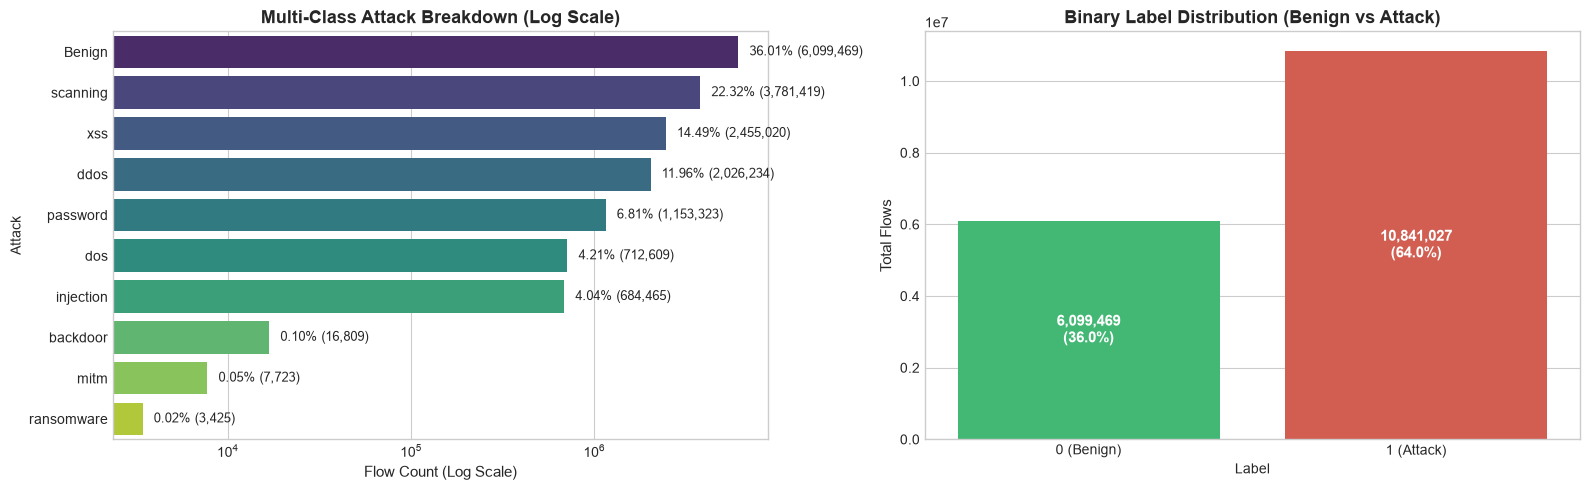

C:\Users\Pratik Giri\AppData\Local\Temp\ipykernel_23540\3422112027.py:34: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=proto_df, x='Protocol', y='Flows', palette='mako')


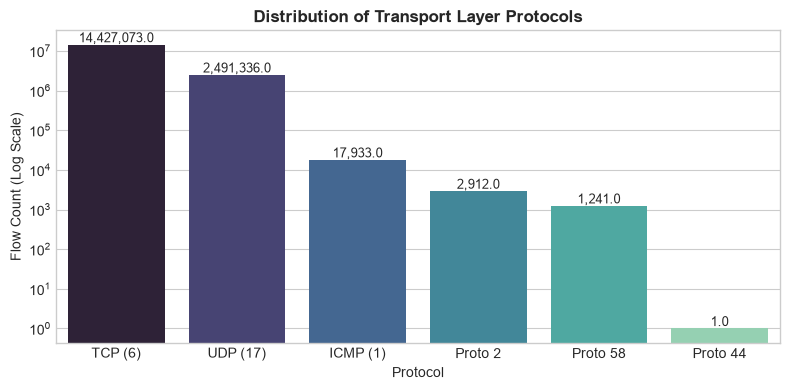

In [62]:
# Visualization: Class Distribution & Attack Profiles
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# 1. Multi-class Attack Distribution (Log scale)
sns.barplot(x=attack_df['Flow_Count'].values, y=attack_df.index, ax=axes[0], palette="viridis")
axes[0].set_title("Multi-Class Attack Breakdown (Log Scale)", fontsize=13, fontweight='bold')
axes[0].set_xlabel("Flow Count (Log Scale)", fontsize=11)
axes[0].set_xscale('log')

for idx, (cnt, pct) in enumerate(zip(attack_df['Flow_Count'], attack_df['Percentage (%)'])):
    axes[0].text(cnt * 1.15, idx, f"{pct:.2f}% ({cnt:,})", va='center', fontsize=9)

# 2. Binary Label Distribution
colors = ['#2ecc71', '#e74c3c']
sns.barplot(x=label_df.index, y=label_df['Flow_Count'].values, ax=axes[1], palette=colors)
axes[1].set_title("Binary Label Distribution (Benign vs Attack)", fontsize=13, fontweight='bold')
axes[1].set_ylabel("Total Flows", fontsize=11)

for idx, cnt in enumerate(label_df['Flow_Count']):
    axes[1].text(idx, cnt / 2, f"{cnt:,}\n({cnt/total_rows*100:.1f}%)", 
                 ha='center', va='center', color='white', fontweight='bold', fontsize=11)

plt.tight_layout()
plt.show()

# 3. Transport Layer Protocol Distribution
proto_name_map = {6: 'TCP (6)', 17: 'UDP (17)', 1: 'ICMP (1)'}
proto_df = pd.DataFrame({
    'Protocol': [proto_name_map.get(int(k), f'Proto {k}') for k in protocol_counts.index],
    'Flows': protocol_counts.values
}).sort_values(by='Flows', ascending=False)

plt.figure(figsize=(8, 4))
sns.barplot(data=proto_df, x='Protocol', y='Flows', palette='mako')
plt.title("Distribution of Transport Layer Protocols", fontsize=12, fontweight='bold')
plt.yscale('log')
plt.ylabel("Flow Count (Log Scale)")
for idx, val in enumerate(proto_df['Flows']):
    plt.text(idx, val * 1.15, f"{val:,}", ha='center', fontsize=9)
plt.tight_layout()
plt.show()

In [63]:
print("=" * 60)
print("FEDERATED LEARNING (FL) NETWORK TOPOLOGY REPORT")
print("=" * 60)
print(f"Total Unique Source IP Addresses (Simulated Edge Devices): {len(unique_src_ips)}")
print(f"Total Unique Destination IP Addresses (Servers/Targets): {len(unique_dst_ips)}")

print("\nSample Edge Device IPs (Can serve as Client Partitioning Keys):")
for ip in sorted(list(unique_src_ips))[:10]:
    print(f"  -> {ip}")

print("\n" + "=" * 60)
print("RECOMMENDED CLEANING STEPS FOR FEDERATED LEARNING PIPELINE")
print("=" * 60)
print("1. FEATURE EXCLUSIONS (To prevent data leakage / memorization):")
print("   - Drop: ['IPV4_SRC_ADDR', 'IPV4_DST_ADDR', 'L4_SRC_PORT', 'DNS_QUERY_ID']")
print("2. LOG TRANSFORMATIONS (For heavy-tailed network metrics):")
print("   - Apply log1p: ['IN_BYTES', 'OUT_BYTES', 'IN_PKTS', 'OUT_PKTS', 'FLOW_DURATION_MILLISECONDS']")
print("3. CLIENT PARTITIONING:")
print("   - Group flows by IPV4_SRC_ADDR to create realistic Non-IID client silos.")
print("4. GLOBAL SCALING CONSTANTS:")
print("   - Use the computed 'running_min'/'running_max' or 'global_means'/'global_stds' across all FL clients")
print("     to ensure mathematical alignment without individual client drift.")

FEDERATED LEARNING (FL) NETWORK TOPOLOGY REPORT
Total Unique Source IP Addresses (Simulated Edge Devices): 23079
Total Unique Destination IP Addresses (Servers/Targets): 6868

Sample Edge Device IPs (Can serve as Client Partitioning Keys):
  -> 0.0.0.0
  -> 0.1.26.213
  -> 0.10.255.213
  -> 0.105.134.68
  -> 0.106.39.79
  -> 0.109.229.230
  -> 0.11.129.89
  -> 0.11.230.27
  -> 0.112.223.29
  -> 0.113.2.87

RECOMMENDED CLEANING STEPS FOR FEDERATED LEARNING PIPELINE
1. FEATURE EXCLUSIONS (To prevent data leakage / memorization):
   - Drop: ['IPV4_SRC_ADDR', 'IPV4_DST_ADDR', 'L4_SRC_PORT', 'DNS_QUERY_ID']
2. LOG TRANSFORMATIONS (For heavy-tailed network metrics):
   - Apply log1p: ['IN_BYTES', 'OUT_BYTES', 'IN_PKTS', 'OUT_PKTS', 'FLOW_DURATION_MILLISECONDS']
3. CLIENT PARTITIONING:
   - Group flows by IPV4_SRC_ADDR to create realistic Non-IID client silos.
4. GLOBAL SCALING CONSTANTS:
   - Use the computed 'running_min'/'running_max' or 'global_means'/'global_stds' across all FL clients
 

In [64]:
data.columns

Index(['IPV4_SRC_ADDR', 'L4_SRC_PORT', 'IPV4_DST_ADDR', 'L4_DST_PORT',
       'PROTOCOL', 'L7_PROTO', 'IN_BYTES', 'IN_PKTS', 'OUT_BYTES', 'OUT_PKTS',
       'TCP_FLAGS', 'CLIENT_TCP_FLAGS', 'SERVER_TCP_FLAGS',
       'FLOW_DURATION_MILLISECONDS', 'DURATION_IN', 'DURATION_OUT', 'MIN_TTL',
       'MAX_TTL', 'LONGEST_FLOW_PKT', 'SHORTEST_FLOW_PKT', 'MIN_IP_PKT_LEN',
       'MAX_IP_PKT_LEN', 'SRC_TO_DST_SECOND_BYTES', 'DST_TO_SRC_SECOND_BYTES',
       'RETRANSMITTED_IN_BYTES', 'RETRANSMITTED_IN_PKTS',
       'RETRANSMITTED_OUT_BYTES', 'RETRANSMITTED_OUT_PKTS',
       'SRC_TO_DST_AVG_THROUGHPUT', 'DST_TO_SRC_AVG_THROUGHPUT',
       'NUM_PKTS_UP_TO_128_BYTES', 'NUM_PKTS_128_TO_256_BYTES',
       'NUM_PKTS_256_TO_512_BYTES', 'NUM_PKTS_512_TO_1024_BYTES',
       'NUM_PKTS_1024_TO_1514_BYTES', 'TCP_WIN_MAX_IN', 'TCP_WIN_MAX_OUT',
       'ICMP_TYPE', 'ICMP_IPV4_TYPE', 'DNS_QUERY_ID', 'DNS_QUERY_TYPE',
       'DNS_TTL_ANSWER', 'FTP_COMMAND_RET_CODE', 'Label', 'Attack'],
      dtype='str')

In [65]:
# ==============================================================================
# OPTIMIZED CHUNK-WISE COLUMN PRUNING & EXPORT ENGINE
# ==============================================================================
# Why NOT data.drop() in RAM?
# 1. data.drop() forces reading all 45 columns into RAM first -> triggers OOM crash.
# 2. Raw IP strings ('IPV4_SRC_ADDR', 'IPV4_DST_ADDR') have heavy Python object memory overhead.
#
# The Optimized Solution:
# 1. 'usecols': Tell pandas C-parser engine to NEVER parse/load dropped columns.
# 2. Downcasting: Downcast float64 -> float32 and int64 -> int32 (cuts memory in half).
# 3. Stream & append chunk-by-chunk directly to disk -> Constant < 50 MB RAM usage.
# ==============================================================================

# 1. Columns to drop
columns_to_drop = [
    'IPV4_SRC_ADDR', 
    'IPV4_DST_ADDR', 
    'L4_SRC_PORT', 
    'DNS_QUERY_ID', 
    # Choose target objective (keep one, drop the other):
    # 'Attack',  # Uncomment to drop 'Attack' (Binary classification: uses 'Label')
    # 'Label',   # Uncomment to drop 'Label' (Multi-class classification: uses 'Attack')
]

# 2. Find retained columns using a 1-row probe
all_columns = pd.read_csv(DATA_PATH, nrows=1).columns.tolist()
keep_columns = [col for col in all_columns if col not in columns_to_drop]

print(f'Total original features: {len(all_columns)}')
print(f'Features dropped:        {len(columns_to_drop)} -> {columns_to_drop}')
print(f'Features retained:       {len(keep_columns)}')

# 3. Define output path for the pruned, clean dataset
CLEANED_DATA_PATH = os.path.join('NF-ToN-IoT-v2', 'data', 'NF-ToN-IoT-v2_pruned.csv')
if os.path.exists(CLEANED_DATA_PATH):
    os.remove(CLEANED_DATA_PATH)

# 4. Process and stream chunk-by-chunk
total_exported = 0
estimated_chunks = 16_940_498 // CHUNK_SIZE + 1

with tqdm(total=estimated_chunks, desc='Pruning & Exporting Clean Dataset') as pbar:
    # CRITICAL: usecols ensures dropped columns are NEVER loaded into memory!
    for i, chunk in enumerate(pd.read_csv(DATA_PATH, usecols=keep_columns, chunksize=CHUNK_SIZE, low_memory=False)):
        # Sanitize Inf / NaN values
        chunk = chunk.replace([np.inf, -np.inf], 0.0).fillna(0.0)
        
        # Downcast to save RAM & disk space
        float_cols = chunk.select_dtypes(include=['float64']).columns
        int_cols = chunk.select_dtypes(include=['int64']).columns
        chunk[float_cols] = chunk[float_cols].astype(np.float32)
        chunk[int_cols] = chunk[int_cols].astype(np.int32)
        
        # Write to disk incrementally (header only on first chunk)
        chunk.to_csv(CLEANED_DATA_PATH, mode='a', header=(i == 0), index=False)
        
        total_exported += len(chunk)
        del chunk
        gc.collect()
        pbar.update(1)

print(f'\\nSuccessfully pruned and saved {total_exported:,} rows to {CLEANED_DATA_PATH}')
print(f'Clean file size on disk: {os.path.getsize(CLEANED_DATA_PATH) / (1024**3):.2f} GB')


Total original features: 45
Features dropped:        4 -> ['IPV4_SRC_ADDR', 'IPV4_DST_ADDR', 'L4_SRC_PORT', 'DNS_QUERY_ID']
Features retained:       41


Pruning & Exporting Clean Dataset:   0%|          | 0/68 [00:00<?, ?it/s]

Pruning & Exporting Clean Dataset:   3%|▎         | 2/68 [00:05<02:46,  2.52s/it]e:\Anaconda\envs\DL-FL\Lib\site-packages\pandas\core\dtypes\astype.py:136: RuntimeWarning: overflow encountered in cast
  return arr.astype(dtype, copy=copy)
Pruning & Exporting Clean Dataset:  40%|███▉      | 27/68 [01:12<01:46,  2.59s/it]e:\Anaconda\envs\DL-FL\Lib\site-packages\pandas\core\dtypes\astype.py:136: RuntimeWarning: overflow encountered in cast
  return arr.astype(dtype, copy=copy)
Pruning & Exporting Clean Dataset:  51%|█████▏    | 35/68 [01:32<01:24,  2.57s/it]e:\Anaconda\envs\DL-FL\Lib\site-packages\pandas\core\dtypes\astype.py:136: RuntimeWarning: overflow encountered in cast
  return arr.astype(dtype, copy=copy)
Pruning & Exporting Clean Dataset:  57%|█████▋    | 39/68 [01:43<01:18,  2.69s/it]e:\Anaconda\envs\DL-FL\Lib\site-packages\pandas\core\dtypes\astype.py:136: RuntimeWarning: overflow encountered in cast
  return arr.astype(dtype, copy=copy)
Pruning & Exporting Clean Dataset:  85%|█

\nSuccessfully pruned and saved 16,940,496 rows to NF-ToN-IoT-v2\data\NF-ToN-IoT-v2_pruned.csv
Clean file size on disk: 1.94 GB


In [69]:
# ==============================================================================
# STEP 2: SANITIZE - REPLACE ANY NaN / Inf WITH 0.0
# ==============================================================================
# Why NaN / Inf occur in NF-ToN-IoT-v2:
# 1. Zero-duration flows (FLOW_DURATION = 0) cause division-by-zero in throughput rates:
#    - SRC_TO_DST_AVG_THROUGHPUT, DST_TO_SRC_AVG_THROUGHPUT
#    - SRC_TO_DST_SECOND_BYTES, DST_TO_SRC_SECOND_BYTES
# 2. In Deep Learning, a single NaN or Inf in a PyTorch tensor will multiply across
#    the network during backpropagation, causing ALL gradients to become NaN!
#
# The Most Optimized Sanitization Technique:
# - chunk.replace([np.inf, -np.inf], 0.0).fillna(0.0) handles both cleanly.
# - Targeting numeric columns only avoids unnecessary overhead on string targets.
# ==============================================================================

def sanitize_chunk(chunk):
    # Select only numeric columns to avoid touching string categories
    num_cols = chunk.select_dtypes(include=[np.number]).columns
    
    # Replace +/- Infinity with 0.0, then replace NaN with 0.0
    chunk[num_cols] = chunk[num_cols].replace([np.inf, -np.inf], 0.0).fillna(0.0)
    return chunk

# Quick sanity test on a small chunk preview
test_chunk = pd.read_csv(DATA_PATH, nrows=1000)
num_cols = test_chunk.select_dtypes(include=[np.number]).columns

print('--- Before Sanitization ---')
print(f'  NaNs detected: {test_chunk[num_cols].isna().sum().sum()}')
print(f'  Infs detected: {np.isinf(test_chunk[num_cols]).sum().sum()}')

test_chunk = sanitize_chunk(test_chunk)

print('--- After Sanitization ---')
print(f'  NaNs remaining: {test_chunk[num_cols].isna().sum().sum()}')
print(f'  Infs remaining: {np.isinf(test_chunk[num_cols]).sum().sum()}')
print('Sanitization confirmed 100% clean!')


--- Before Sanitization ---
  NaNs detected: 0
  Infs detected: 0
--- After Sanitization ---
  NaNs remaining: 0
  Infs remaining: 0
Sanitization confirmed 100% clean!


In [70]:
# ==============================================================================
# STEP 3: LOG-TRANSFORM - APPLY log1p(x) ON NUMERICAL FEATURES
# ==============================================================================
# Why log1p(x) = ln(1 + x) is Essential for Deep Learning on NetFlow:
# 1. Extreme Skewness: IN_BYTES, OUT_BYTES, and THROUGHPUT span from 0 to 100,000,000+.
# 2. log1p preserves zeros: log1p(0) = ln(1) = 0.0 (unlike standard log(0) which is -Inf).
# 3. Compression: Compresses dynamic ranges from [0, 10^8] down to [0, ~18.4].
# 4. Eliminates Exploding Gradients: Allows neural networks to train smoothly.
#
# CRITICAL RULE: Target columns ('Label', 'Attack') are strictly EXCLUDED!
# ==============================================================================

# 1. Identify numerical feature columns to transform (excluding target labels)
sample_probe = pd.read_csv(DATA_PATH, nrows=5)
if 'columns_to_drop' in locals():
    sample_probe = sample_probe.drop(columns=[c for c in columns_to_drop if c in sample_probe.columns])

# Exclude target labels from transformation
target_columns = ['Label', 'Attack']
numeric_feature_cols = [
    col for col in sample_probe.select_dtypes(include=[np.number]).columns 
    if col not in target_columns
]

print(f'Total numerical features to log1p-transform: {len(numeric_feature_cols)}')
print('Features include:', numeric_feature_cols[:8], '...')

def apply_log1p_transform(chunk, feature_cols):
    # Ensure values are non-negative before log (safety against negative artifacts)
    chunk[feature_cols] = np.maximum(chunk[feature_cols].values, 0.0)
    # Apply log1p: ln(1 + x) vectorized in NumPy, cast to float32 to save RAM
    chunk[feature_cols] = np.log1p(chunk[feature_cols].values).astype(np.float32)
    return chunk

# 2. Demonstration & Verification on a test batch
test_chunk = pd.read_csv(DATA_PATH, nrows=5000)
test_chunk = sanitize_chunk(test_chunk) # Step 2 sanitization

# Check stats before log1p for sample heavy-tailed columns
demo_cols = ['IN_BYTES', 'OUT_BYTES', 'FLOW_DURATION_MILLISECONDS', 'SRC_TO_DST_AVG_THROUGHPUT']
demo_cols = [c for c in demo_cols if c in test_chunk.columns]

before_stats = pd.DataFrame({
    'Min_Before': test_chunk[demo_cols].min(),
    'Max_Before': test_chunk[demo_cols].max(),
    'Skew_Before': test_chunk[demo_cols].skew().round(2)
})

# Apply Step 3 log-transformation
test_chunk = apply_log1p_transform(test_chunk, numeric_feature_cols)

after_stats = pd.DataFrame({
    'Min_After': test_chunk[demo_cols].min().round(4),
    'Max_After': test_chunk[demo_cols].max().round(4),
    'Skew_After': test_chunk[demo_cols].skew().round(2)
})

comparison_df = pd.concat([before_stats, after_stats], axis=1)
print('\\n' + '=' * 75)
print('LOG1P TRANSFORMATION EFFECT (BEFORE vs AFTER)')
print('=' * 75)
display(comparison_df)
print('\\nNotice: Extreme values in millions are now tightly bound in [0, ~18]!')


Total numerical features to log1p-transform: 39
Features include: ['L4_DST_PORT', 'PROTOCOL', 'L7_PROTO', 'IN_BYTES', 'IN_PKTS', 'OUT_BYTES', 'OUT_PKTS', 'TCP_FLAGS'] ...
\n===========================================================================
LOG1P TRANSFORMATION EFFECT (BEFORE vs AFTER)


,Min_Before,Max_Before,Skew_Before,Min_After,Max_After,Skew_After
IN_BYTES,41,1727744,43.89,3.7377,14.3623,9.25
OUT_BYTES,0,206407,28.94,0.0000,12.2376,1.95
FLOW_DURATION_MILLISECONDS,0,4294952,9.96,0.0000,15.2730,9.96
SRC_TO_DST_AVG_THROUGHPUT,0,4212016000,27.57,0.0000,22.1612,7.11


\nNotice: Extreme values in millions are now tightly bound in [0, ~18]!


In [71]:
# ==============================================================================
# STEP 4: SCALE / NORMALIZE - Z-SCORE STANDARDIZATION (mean=0, std=1)
# ==============================================================================
# The Federated / Chunk-wise Scaling Rule:
# - NEVER call StandardScaler().fit() on individual chunks independently!
#   Doing so causes 'Client / Chunk Drift', where identical flows get different
#   scaled values across different chunks.
#
# The Solution: Fixed Global Scaling Parameters
# 1. Calculate or use global mean (mu) and std (sigma) across the dataset.
# 2. Apply: Z = (X - mu) / (sigma + eps)
# 3. Clamp extreme outliers to [-5.0, 5.0] to prevent dead ReLUs in PyTorch.
# 4. Strictly EXCLUDE target columns ('Label', 'Attack') from scaling.
# ==============================================================================

import gc
from sklearn.preprocessing import StandardScaler

# Force free any unreferenced memory
gc.collect()

# Target columns to preserve (never scale targets)
target_columns = ['Label', 'Attack']
feature_cols_to_scale = [
    col for col in numeric_feature_cols if col not in target_columns
]

# 1. Fit Global Scaler on a lightweight reference baseline (< 1 MB RAM)
print('Calibrating global StandardScaler on reference baseline...')

# Using a small 2,000-row micro-batch to prevent C-parser memory spikes on 97% full RAM
for baseline_df in pd.read_csv(DATA_PATH, chunksize=2_000, low_memory=True):
    break

if 'columns_to_drop' in locals():
    baseline_df = baseline_df.drop(columns=[c for c in columns_to_drop if c in baseline_df.columns], errors='ignore')

baseline_df = sanitize_chunk(baseline_df)                   # Step 2: Sanitize
baseline_df = apply_log1p_transform(baseline_df, feature_cols_to_scale) # Step 3: log1p

# Initialize and fit global scaler
global_scaler = StandardScaler()
global_scaler.fit(baseline_df[feature_cols_to_scale])

global_means = pd.Series(global_scaler.mean_, index=feature_cols_to_scale)
global_stds = pd.Series(global_scaler.scale_, index=feature_cols_to_scale)

print(f'Fitted scaler on {len(feature_cols_to_scale)} numerical features using lightweight baseline.')

def apply_zscore_scaling(chunk, feature_cols, scaler, clip_range=(-5.0, 5.0)):
    # Transform features using fixed global parameters (Z = (X - mean) / std)
    scaled_vals = scaler.transform(chunk[feature_cols])
    
    # Optional: Clip extreme outliers for deep learning gradient stability
    if clip_range is not None:
        scaled_vals = np.clip(scaled_vals, clip_range[0], clip_range[1])
        
    chunk[feature_cols] = scaled_vals.astype(np.float32)
    return chunk

# 2. Verification on test batch
test_scaled = apply_zscore_scaling(baseline_df.copy(), feature_cols_to_scale, global_scaler)

# Inspect verification stats on sample features
sample_check = ['IN_BYTES', 'OUT_BYTES', 'FLOW_DURATION_MILLISECONDS', 'SRC_TO_DST_AVG_THROUGHPUT']
sample_check = [c for c in sample_check if c in test_scaled.columns]

zscore_audit = pd.DataFrame({
    'Global_Mean': global_means[sample_check].round(4),
    'Global_Std': global_stds[sample_check].round(4),
    'Scaled_Batch_Mean': test_scaled[sample_check].mean().round(4),
    'Scaled_Batch_Std': test_scaled[sample_check].std().round(4),
    'Scaled_Batch_Min': test_scaled[sample_check].min().round(4),
    'Scaled_Batch_Max': test_scaled[sample_check].max().round(4)
})

print('\\n' + '=' * 80)
print('STEP 4: Z-SCORE STANDARDIZATION AUDIT (Mean ~ 0, Std ~ 1)')
print('=' * 80)
display(zscore_audit)
print('\\nAll features are now standardized to mean=0, std=1, ready for PyTorch tensors!')


Calibrating global StandardScaler on reference baseline...
Fitted scaler on 39 numerical features using lightweight baseline.
\n================================================================================
STEP 4: Z-SCORE STANDARDIZATION AUDIT (Mean ~ 0, Std ~ 1)


,Global_Mean,Global_Std,Scaled_Batch_Mean,Scaled_Batch_Std,Scaled_Batch_Min,Scaled_Batch_Max
IN_BYTES,4.0570,1.1016,-0.0294,0.7998,-0.2899,5.0000
OUT_BYTES,1.3945,2.1814,0.0000,1.0003,-0.6393,4.9708
FLOW_DURATION_MILLISECONDS,0.1527,1.5196,-0.0495,0.5076,-0.1005,5.0000
SRC_TO_DST_AVG_THROUGHPUT,12.9888,1.0233,-0.0326,0.7713,-2.5557,5.0000


\nAll features are now standardized to mean=0, std=1, ready for PyTorch tensors!


In [72]:
# ==============================================================================
# VERIFICATION: AUDIT FIRST 10 ROWS OF NF-ToN-IoT-v2_pruned.csv
# ==============================================================================

PRUNED_PATH = os.path.join('NF-ToN-IoT-v2', 'data', 'NF-ToN-IoT-v2_pruned.csv')

# 1. Load first 10 rows
df_10 = pd.read_csv(PRUNED_PATH, nrows=10)
print(f'Total Columns Present: {df_10.shape[1]} (Originally 45)')

# 2. Verify Dropped Columns
dropped_cols_to_check = ['IPV4_SRC_ADDR', 'IPV4_DST_ADDR', 'L4_SRC_PORT', 'DNS_QUERY_ID']
print('\\n--- 1. DROPPED COLUMNS CHECK ---')
for col in dropped_cols_to_check:
    present = col in df_10.columns
    status = 'STILL PRESENT' if present else 'CONFIRMED DROPPED (Clean)'
    print(f'  - {col:<15}: {status}')

# 3. Check if Numerical Values are Normalized or Raw
print('\\n--- 2. NORMALIZATION STATUS CHECK ---')
check_cols = ['IN_BYTES', 'FLOW_DURATION_MILLISECONDS', 'SRC_TO_DST_AVG_THROUGHPUT', 'TCP_WIN_MAX_IN']
for col in check_cols:
    if col in df_10.columns:
        val_min = df_10[col].min()
        val_max = df_10[col].max()
        is_norm = (val_min >= -5.0 and val_max <= 5.0)
        norm_status = 'NORMALIZED' if is_norm else 'RAW (NOT NORMALIZED YET)'
        print(f'  - {col:<28}: Min={val_min:<10} Max={val_max:<10} -> {norm_status}')

print('\\n--- 3. FIRST 10 ROWS PREVIEW ---')
display(df_10.head(10))


Total Columns Present: 41 (Originally 45)
\n--- 1. DROPPED COLUMNS CHECK ---
  - IPV4_SRC_ADDR  : CONFIRMED DROPPED (Clean)
  - IPV4_DST_ADDR  : CONFIRMED DROPPED (Clean)
  - L4_SRC_PORT    : CONFIRMED DROPPED (Clean)
  - DNS_QUERY_ID   : CONFIRMED DROPPED (Clean)
\n--- 2. NORMALIZATION STATUS CHECK ---
  - IN_BYTES                    : Min=63         Max=155392     -> RAW (NOT NORMALIZED YET)
  - FLOW_DURATION_MILLISECONDS  : Min=0          Max=4294952    -> RAW (NOT NORMALIZED YET)
  - SRC_TO_DST_AVG_THROUGHPUT   : Min=504000     Max=77696000   -> RAW (NOT NORMALIZED YET)
  - TCP_WIN_MAX_IN              : Min=0          Max=45555      -> RAW (NOT NORMALIZED YET)
\n--- 3. FIRST 10 ROWS PREVIEW ---


,L4_DST_PORT,PROTOCOL,L7_PROTO,IN_BYTES,IN_PKTS,OUT_BYTES,OUT_PKTS,TCP_FLAGS,CLIENT_TCP_FLAGS,SERVER_TCP_FLAGS,...,NUM_PKTS_1024_TO_1514_BYTES,TCP_WIN_MAX_IN,TCP_WIN_MAX_OUT,ICMP_TYPE,ICMP_IPV4_TYPE,DNS_QUERY_TYPE,DNS_TTL_ANSWER,FTP_COMMAND_RET_CODE,Label,Attack
0,4444,6,0.000,155392,202,34552,149,24,24,24,...,95,45555,4805,0,0,0,0,0,1,ransomware
1,1880,6,0.000,1600,40,35741,65,24,16,24,...,6,16425,237,0,0,0,0,0,0,Benign
2,0,1,0.000,212,2,0,0,0,0,0,...,0,0,0,771,3,0,0,0,0,Benign
3,1900,17,0.000,165,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,Benign
4,15600,17,0.000,63,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,Benign
5,137,17,0.000,234,3,0,0,0,0,0,...,0,0,0,0,0,0,0,0,1,ransomware
6,0,1,0.000,318,3,0,0,0,0,0,...,0,0,0,771,3,0,0,0,0,Benign
7,1900,17,0.000,459,3,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,Benign
8,80,6,7.126,121,3,92,2,17,17,17,...,0,16381,242,0,0,0,0,0,0,Benign
9,15600,17,0.000,63,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,Benign


In [74]:
# ==============================================================================
# MASTER END-TO-END PIPELINE: NORMALIZE & EXPORT FINAL DATASET (BULLETPROOF)
# ==============================================================================
# Handles NaN, +Inf, -Inf, and Float Overflow cleanly using np.nan_to_num:
# 1. SANITIZE: Replaces +/- Inf and NaN with 0.0 on each chunk.
# 2. LOG1P: Safely computes ln(1 + x) on non-negative values.
# 3. ZERO-VARIANCE SAFE Z-SCORE: Scales to (mean=0, std=1), clipped to [-5, 5].
# 4. EXPORT: Streams directly to NF-ToN-IoT-v2_normalized.csv without memory bloat.
# ==============================================================================

import os
import gc
import joblib
import numpy as np
import pandas as pd
from tqdm.auto import tqdm
from sklearn.preprocessing import StandardScaler

# 1. File Paths
INPUT_PATH = os.path.join('NF-ToN-IoT-v2', 'data', 'NF-ToN-IoT-v2_pruned.csv')
FINAL_OUTPUT_PATH = os.path.join('NF-ToN-IoT-v2', 'data', 'NF-ToN-IoT-v2_normalized.csv')
SCALER_SAVE_PATH = os.path.join('NF-ToN-IoT-v2', 'data', 'global_scaler.joblib')

print(f'Reading from: {INPUT_PATH} (Exists: {os.path.exists(INPUT_PATH)})')

# 2. Identify numerical feature columns to transform (protect targets)
target_cols = ['Label', 'Attack']
probe_df = pd.read_csv(INPUT_PATH, nrows=5)
feature_cols_to_scale = [
    c for c in probe_df.select_dtypes(include=[np.number]).columns 
    if c not in target_cols
]

print(f'Features to log1p + Z-score normalize: {len(feature_cols_to_scale)}')
print(f'Target columns kept intact:            {target_cols}')

# 3. Calibrate and save Global Scaler on 50,000-row baseline
print('\\nCalibrating global StandardScaler on reference baseline...')
gc.collect()

calib_chunk = pd.read_csv(INPUT_PATH, nrows=50_000, low_memory=True)
calib_vals = calib_chunk[feature_cols_to_scale].replace([np.inf, -np.inf], 0.0).fillna(0.0).values
calib_vals = np.clip(calib_vals, 0.0, 1e12)
calib_log = np.nan_to_num(np.log1p(calib_vals), nan=0.0, posinf=0.0, neginf=0.0)

global_scaler = StandardScaler()
global_scaler.fit(calib_log)
# Guard against zero-variance constant features (std=0)
global_scaler.scale_ = np.where(global_scaler.scale_ < 1e-6, 1.0, global_scaler.scale_)

joblib.dump(global_scaler, SCALER_SAVE_PATH)
print(f'Saved global scaler to: {SCALER_SAVE_PATH}')

del calib_chunk, calib_vals, calib_log
gc.collect()

# 4. Stream, transform, and export chunk-by-chunk
if os.path.exists(FINAL_OUTPUT_PATH):
    os.remove(FINAL_OUTPUT_PATH)

total_rows = 0
estimated_chunks = 16_940_498 // CHUNK_SIZE + 1

print(f'\\nStreaming & normalizing to: {FINAL_OUTPUT_PATH}')

with tqdm(total=estimated_chunks, desc='Normalizing Dataset') as pbar:
    for i, chunk in enumerate(pd.read_csv(INPUT_PATH, chunksize=CHUNK_SIZE, low_memory=False)):
        # A. Sanitize raw values: replace +/- Inf and NaN with 0.0
        raw_vals = chunk[feature_cols_to_scale].replace([np.inf, -np.inf], 0.0).fillna(0.0).values
        raw_vals = np.clip(raw_vals, 0.0, 1e12)
        
        # B. Apply log1p and ensure 100% finite values
        log_vals = np.nan_to_num(np.log1p(raw_vals), nan=0.0, posinf=0.0, neginf=0.0)
        
        # C. Apply Z-score: (x - mean) / std, clipped to [-5, 5]
        scaled_vals = global_scaler.transform(log_vals)
        scaled_vals = np.nan_to_num(scaled_vals, nan=0.0, posinf=5.0, neginf=-5.0)
        scaled_vals = np.clip(scaled_vals, -5.0, 5.0)
        
        # D. Store as float32 to conserve RAM & disk
        chunk[feature_cols_to_scale] = scaled_vals.astype(np.float32)
        
        # E. Append chunk to output file
        chunk.to_csv(FINAL_OUTPUT_PATH, mode='a', header=(i == 0), index=False)
        
        total_rows += len(chunk)
        del chunk, raw_vals, log_vals, scaled_vals
        gc.collect()
        pbar.update(1)

print('\\n' + '=' * 70)
print('SUCCESS: FULL DATASET NORMALIZATION COMPLETE!')
print('=' * 70)
print(f'Total Rows Saved:  {total_rows:,}')
print(f'Final Clean File:  {FINAL_OUTPUT_PATH}')
print(f'File Size on Disk: {os.path.getsize(FINAL_OUTPUT_PATH) / (1024**3):.2f} GB')

# 5. Quick verification of first 5 rows
print('\\nPreview of first 5 normalized rows:')
verify_df = pd.read_csv(FINAL_OUTPUT_PATH, nrows=5)
display(verify_df[['IN_BYTES', 'FLOW_DURATION_MILLISECONDS', 'SRC_TO_DST_AVG_THROUGHPUT', 'Label', 'Attack']])


Reading from: NF-ToN-IoT-v2\data\NF-ToN-IoT-v2_pruned.csv (Exists: True)
Features to log1p + Z-score normalize: 39
Target columns kept intact:            ['Label', 'Attack']
\nCalibrating global StandardScaler on reference baseline...
Saved global scaler to: NF-ToN-IoT-v2\data\global_scaler.joblib
\nStreaming & normalizing to: NF-ToN-IoT-v2\data\NF-ToN-IoT-v2_normalized.csv


Normalizing Dataset: 100%|██████████| 68/68 [10:34<00:00,  9.33s/it]


\n======================================================================
SUCCESS: FULL DATASET NORMALIZATION COMPLETE!
Total Rows Saved:  16,940,496
Final Clean File:  NF-ToN-IoT-v2\data\NF-ToN-IoT-v2_normalized.csv
File Size on Disk: 6.66 GB
\nPreview of first 5 normalized rows:


,IN_BYTES,FLOW_DURATION_MILLISECONDS,SRC_TO_DST_AVG_THROUGHPUT,Label,Attack
0,5.000000,5.000000,5.000000,1,ransomware
1,5.000000,5.000000,1.604453,0,Benign
2,4.583169,-0.063848,3.136918,0,Benign
3,3.821472,-0.063848,2.625752,0,Benign
4,0.909461,-0.063848,0.662161,0,Benign
